# AP 155 Lab Exercise
---
## Exercise 9: Interpolation

_Instructions_:
- **Report figures:** Compare the original data with interpolated reconstructions. Include the synthetic sine example and the sampled real-world dataset, if available. For the real-world dataset, compare sampling levels of 50%, 30%, 10%, and 5%.
- **Report discussion:** Explain how the choice of interpolator and sampling level affects the reconstruction. Discuss limitations, including behavior outside the sampled domain.
- **Code:** Complete the code and ensure it is functional, readable, and efficient. Include concise Markdown documentation highlighting the critical steps.

### Student Information
- _Full Name (Last Name, First Name)_: Buhangin, Ahrystan Deniz
- _Student No._: 2024-07766
- _Section_: THR-TX-1

### Grading Information (c/o Lab Instructor)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figures | XX | 20 |
| Report discussion | XX | 20 |
| Code readability | XX | 20 |
| Code efficiency | XX | 20 |
| Code appropriateness | XX | 20 |
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_

---
## Section 1: Report

### Report figures

**Figure 1. Synthetic data interpolation.** 

<img src="Figures/interp_sine.png" alt="Minimization" width=45%>

**Figure 2. Real-world data reconstruction.**

<img src="Figures/interp_dow_varsamp.png" alt="Minimization" width=45%>

### Report discussion

**Interpolator comparison:** Linear interpolation creates a line directly between each data point, which results in fast calculations, but discontinuities between points. Nearest interpolation, on the other hand, assigns intermediate values to whichever data point is closest to it. This visually results in blocky interpolations which have harsh discontinuities. Quadratic interpolations force second-order polynomials to fit between data points, which results in a smooth curve that is continuous in both the function, and its first derivative. Cubic spline interpolations instead force third-order polynomials to fit between data points, which also results in a smooth curve that is continuous in the function, its first derivative, and its second derivative. Generally, the trade-off for natural looking curves, or better fitting is calculation time. In the case of our sinusoidal function in problem 1, both the cubic and quadratic fitting look the best but are nigh-indistinguishable from each other.

**Sampling-level comparison:** Reconstruction quality generally increases as we increase our sampling, this makes sense as we simply move closer to a more complete reconstruction with more data points. This is in assumption, of course, that our sampling is not concentrated onto small intervals or regions which can mislead the reconstruction. Crucically, there are cases where a small sampling size causes notable features of the true data to be glossed over. For example, in our Dow dataset, it is not rare for the 5% sampling ratio to undermine the dip around the time of the great market crash. It also goes without saying that increasing the sample size increases computational time, especially when we use higher order interpolations.

### Other comments
- EDIT ME
- A self-reflection can be placed here. This portion is not graded.

---
## Section 2: Code

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import interpolate
from pathlib import Path

rng = np.random.default_rng(42)

### Problem 1: Interpolation of synthetic data

Generate random samples from a known sine function, then compare several interpolation methods. The interpolators only reconstruct values within the sampled domain; they should not be treated as reliable extrapolators outside it.

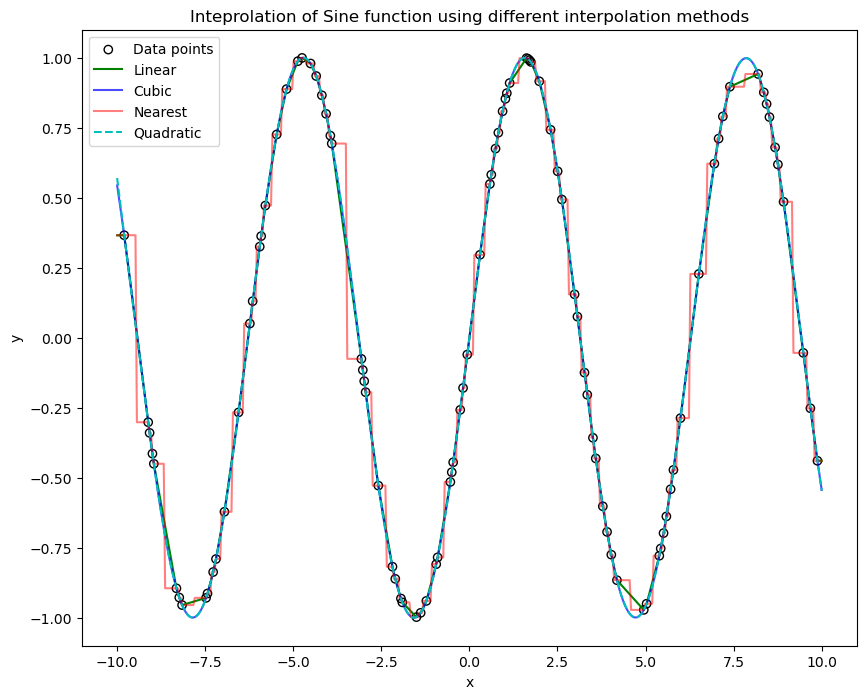

In [2]:
X = np.linspace(-10, 10, 500)
sample_size = 100

def f(x):
    return np.sin(x)

# create all the interpolations
X_sample = np.random.choice(X, sample_size, replace=False)
X_sample.sort()
Y_sample = f(X_sample)
Y_interp = np.interp(X, X_sample, Y_sample, period=360)
Y_cubic = interpolate.CubicSpline(X_sample, Y_sample)
Y_nearest = interpolate.interp1d(X_sample, Y_sample, kind='nearest', fill_value="extrapolate")
Y_quadratic = interpolate.interp1d(X_sample, Y_sample, kind='quadratic', fill_value='extrapolate')

# graph all in one plot
plt.figure(figsize=(10, 8))
plt.scatter(X_sample, Y_sample, label='Data points', facecolors='none', edgecolors='black')
plt.plot(X, Y_interp, 'g', label='Linear')
plt.plot(X, Y_cubic(X), 'b', alpha=0.7, label='Cubic')
plt.plot(X, Y_nearest(X), 'r', alpha=0.5, label='Nearest')
plt.plot(X, Y_quadratic(X),'c--', label='Quadratic')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.title('Inteprolation of Sine function using different interpolation methods')
plt.savefig('/home/jovyan/Buhangin_AP155/AP155_TX1_1sAY2627/ahrystanB/Figures/interp_sine.png')

### Problem 1 code summary


We start by randomly sampling some number of points in the x axis to create an array of data points. These data points are then used to interpolate the original sine function. The code implements linear, nearest, cubic, and quadratic interpolations--which are then graphed in the same plot to showcase their differences.

---

### Problem 2: Interpolation of real-world data

Load the Dow Jones time-series dataset, randomly retain a specified fraction of observations, and compare the reconstructed curve with the original series. The sampling fractions are 50%, 30%, 10%, and 5%. 

In [3]:
#!wget --quiet https://www-personal.umich.edu/~mejn/cp/data/dow.txt

In [4]:
filepath = 'ex9_raw_data.txt'
Raw = np.loadtxt(filepath)

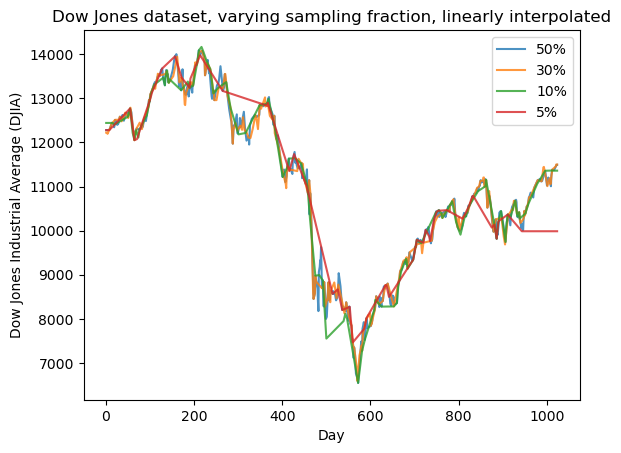

In [5]:
Size = 1024

# Create an array containing all the x values in the data set, on which we will use our interpolations.
X_lst = []
for i in range(1, Size): X_lst.append(i)
X = np.array(X_lst)

# Define a function that produces an ordered sample from data
def getSample(ratio, Size=1024):
    y_sample = []
    x_sample = []
    for i in range(1, Size):
        rand = np.random.rand()
        if rand < ratio:
            y_sample.append(Raw[i])
            x_sample.append(i)
    return y_sample, x_sample

Y_50, X_50 = np.array(getSample(0.5))
Y_30, X_30 = np.array(getSample(0.3))
Y_10, X_10 = np.array(getSample(0.1))
Y_05, X_05 = np.array(getSample(0.05))

lin_50 = np.interp(X, X_50, Y_50)
lin_30 = np.interp(X, X_30, Y_30)
lin_10 = np.interp(X, X_10, Y_10)
lin_05 = np.interp(X, X_05, Y_05)
llin_50 = interpolate.interp1d(X_50, Y_50, 'linear', fill_value='extrapolate')

# plt.scatter(X_50, Y_50, facecolors='none', edgecolors='black')

plt.plot(X, lin_50, alpha=0.8, label='50%')
plt.plot(X, lin_30, alpha=0.8, label='30%')
plt.plot(X, lin_10, alpha=0.8, label='10%')
plt.plot(X, lin_05, alpha=0.8, label='5%')
plt.title('Dow Jones dataset, varying sampling fraction, linearly interpolated')
plt.xlabel("Day")
plt.ylabel("Dow Jones Industrial Average (DJIA)")
plt.legend()
plt.savefig('/home/jovyan/Buhangin_AP155/AP155_TX1_1sAY2627/ahrystanB/Figures/interp_dow_varsamp.png')

### Problem 2  code summary


The above code, first and foremost, extracts the Jones Dow dataset online and imports it into a NumPy array. We then define a function which produces an ordered, randomized sample depending on the provided sampling fraction parameter. Lastly, we create a linear interpolation for each sampling fractions ranging from 50% to 5%. and graph them in the same plot as a visualization.

---

### Problem 3: Compare interpolation methods on the sampled real-world data

Use a single sampling fraction to compare linear, quadratic, and cubic interpolation. Higher-order interpolation can produce smoother curves, but it can also overshoot between sparse or rapidly changing observations.

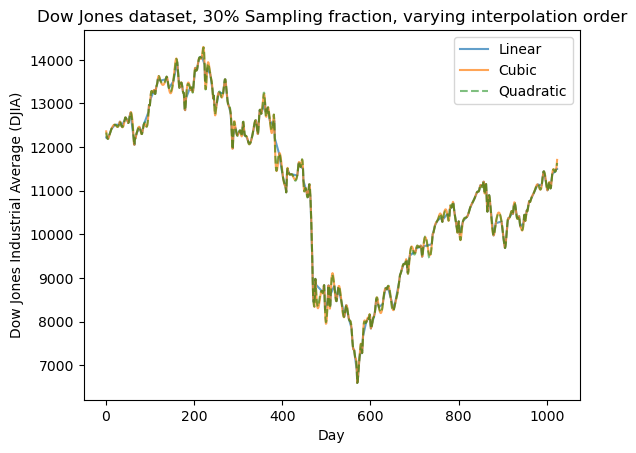

In [6]:
# Define needed interpolations
cubic_30 = interpolate.interp1d(X_30, Y_30, 'cubic', fill_value='extrapolate')
quadratic_30 = interpolate.interp1d(X_30, Y_30, 'quadratic', fill_value='extrapolate')

plt.plot(X, lin_30, alpha=0.7, label='Linear')
plt.plot(X, cubic_30(X), alpha=0.7 ,label='Cubic')
plt.plot(X, quadratic_30(X), 'g--', alpha=0.5, label='Quadratic')
plt.title('Dow Jones dataset, 30% Sampling fraction, varying interpolation order')
plt.xlabel('Day')
plt.ylabel('Dow Jones Industrial Average (DJIA)')
plt.legend()
plt.savefig('/home/jovyan/Buhangin_AP155/AP155_TX1_1sAY2627/ahrystanB/Figures/interp_dow_varint.png')

### Problem 3 code summary


For problem 3, we simply define a cubic and quadratic interpolation for a chosen sampling fraction, in addition to its already defined linear interpolation in problem 2. All three of these are then graphed in the same plot for visualization.

---